# Example of Residual Energy After DPA Activation
This notebook is an example of using the [NASCTN CBRS SEA data set](https://data.nist.gov/od/id/mds2-4214) to measure residual energy after a DPA activation. 

## Imports 

In [1]:
import os,sys
sys.path.append(os.path.join(os.getcwd(),"../"))
from nasctn_sea_visualization import *
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import matplotlib.dates as mdates
import pandas as pd

Importing nasctn_sea_visualization.data_models
It took 2.064305 s to import nasctn_sea_visualization.data_models
Importing nasctn_sea_visualization.plotters


It took 2.838556 s to import nasctn_sea_visualization.plotters
It took 4.902861 s to import all of the active modules


## Data Ingest

In [2]:
# Update path to your copy or https://data.nist.gov/od/ds/mds2-4214/Summaries/2025_03.csv
march_2025_summary = pd.read_csv(r"Y:\Tier2\Summaries\2025_03.csv")

In [3]:
hu_20250315 = DayBlock(file_path =  r"C:\Users\sandersa\Box\SEA-DATA\Raw Data\2025-03-15_HU.zip")

In [4]:
max_psd = hu_20250315.get_day_psd(capture_statistic='max', save=False, save_type='csv')
median_psd = hu_20250315.get_day_psd(capture_statistic='median', save=False, save_type='csv')

In [5]:
channel = 3635e6
pfp_peak_max = hu_20250315.get_aligned_pfp(channel=channel,capture_statistic='max', detector='peak', save=False, save_type='csv')

In [6]:
cbsd_time = pd.to_datetime("2025-03-28 7:30:00",utc = True)
incumbent_time = pd.to_datetime("2025-03-28 10:30:00",utc = True)
noise_time = pd.to_datetime("2025-03-28 12:30:00",utc = True)

In [ ]:
cbsd_single = DataProduct(hu_20250315.get_single(cbsd_time))
incumbent_single = DataProduct(hu_20250315.get_single(incumbent_time))
noise_single = DataProduct(hu_20250328.get_single(noise_time))

## Plotting

In [6]:
start_time = pd.to_datetime("2025-03-15 14:00:00",utc = True)
stop_time = pd.to_datetime("2025-03-15 20:00:00",utc = True)
start_frequency = 3550
stop_frequency = 3650

### PSD and PFP

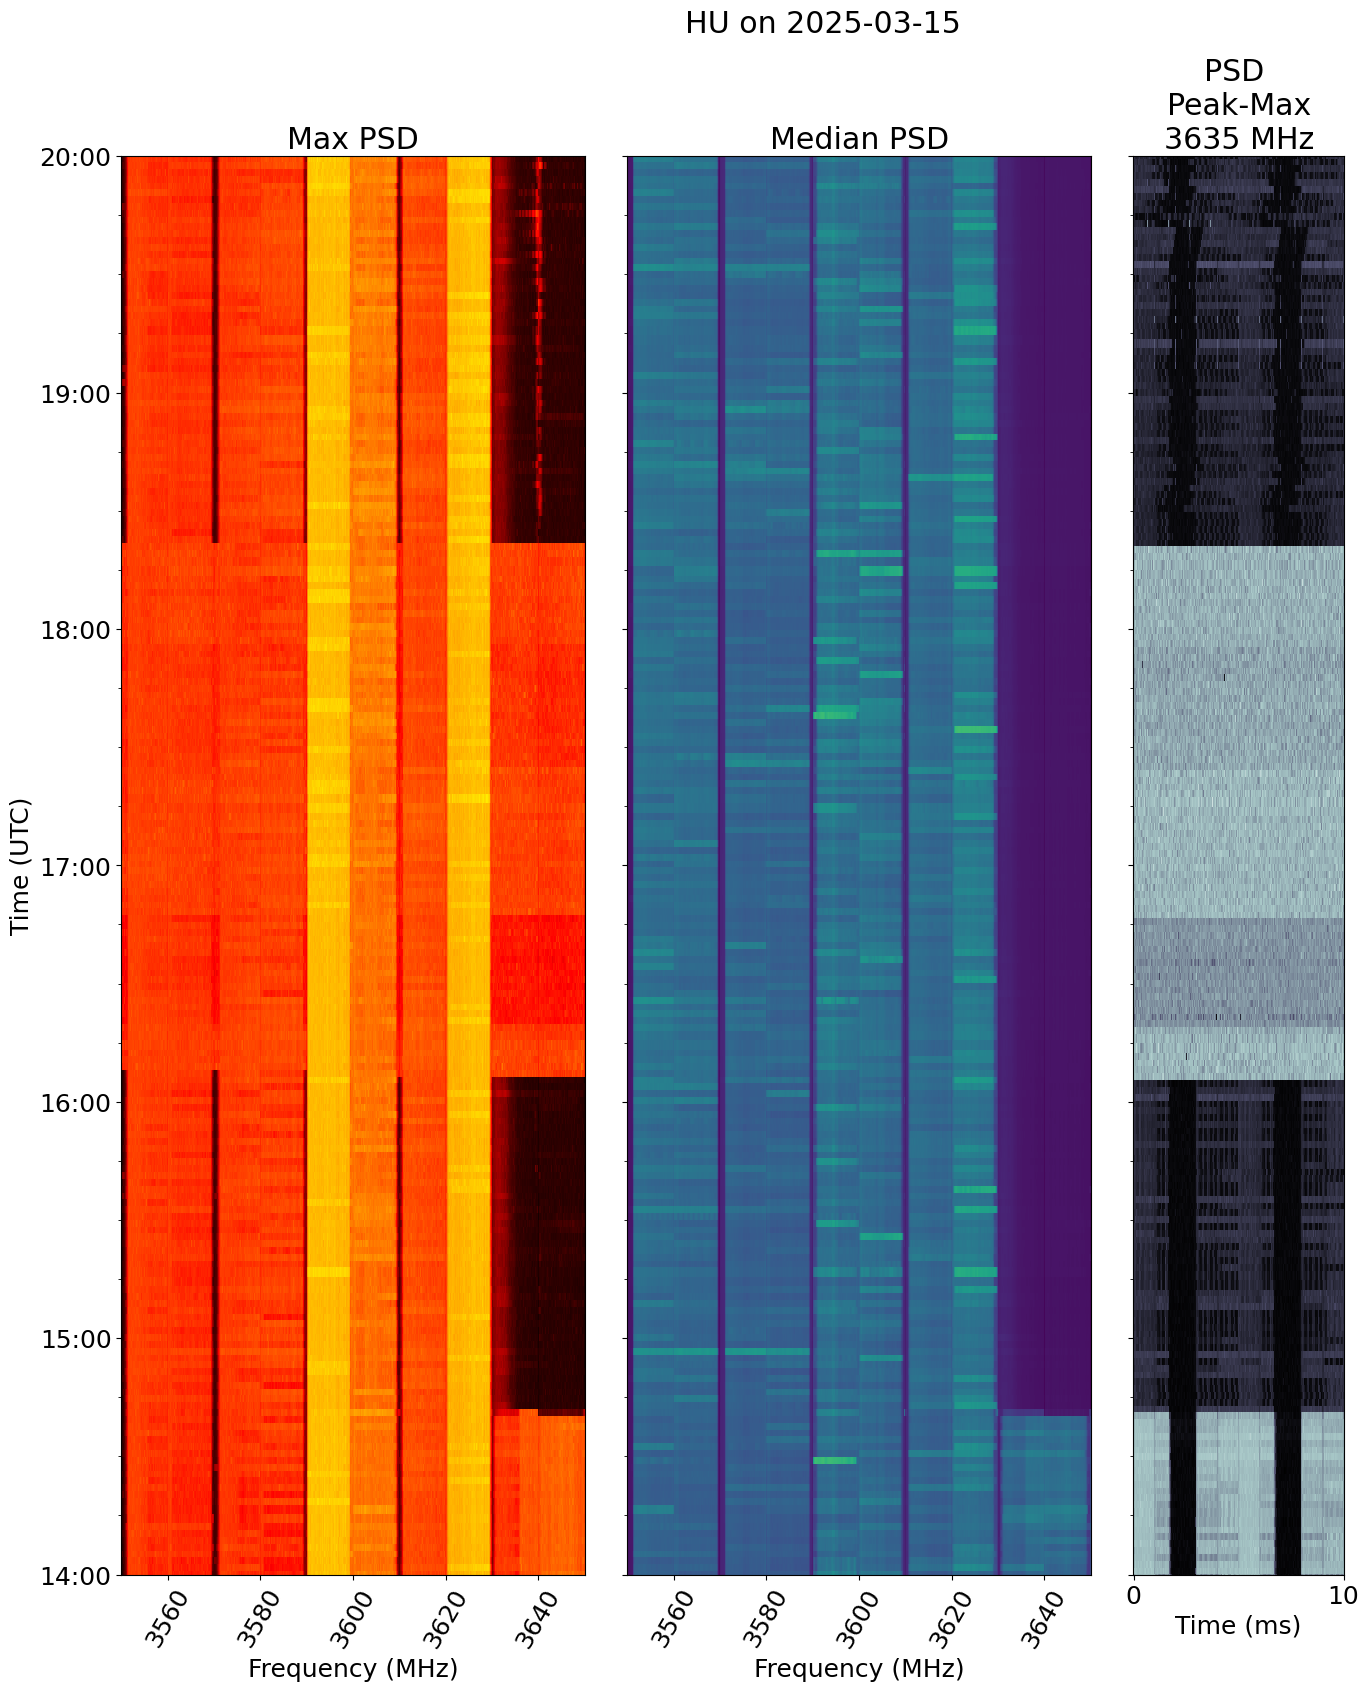

In [ ]:

plt.rcParams.update({"font.size":18})
figure = plt.figure(figsize=(72/3,52/3))
# Setup Gridspec
gs = matplotlib.gridspec.GridSpec(8,9)    
##########################################
psd_max_ax = figure.add_subplot(gs[:,0:2])
psd_median_ax = figure.add_subplot(gs[:,2:4],sharex=psd_max_ax,sharey=psd_max_ax)
pfp_ax = figure.add_subplot(gs[:,4],sharey=psd_max_ax)
#########################################

# Max PSD Axis
colormesh = psd_max_ax.pcolormesh(1e-6*max_psd.columns.astype(float),max_psd.index,max_psd,cmap="hot")
psd_max_ax.yaxis.set_minor_locator(mdates.MinuteLocator(interval = 15))
psd_max_ax.yaxis.set_major_locator(mdates.HourLocator(interval=1))
psd_max_ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
psd_max_ax.set_ylim([start_time,stop_time])
psd_max_ax.set_xlim([start_frequency,stop_frequency])
psd_max_ax.set_title("Max PSD")
psd_max_ax.tick_params("x",labelbottom=True,rotation=60)
psd_max_ax.set_ylabel("Time (UTC)")
psd_max_ax.set_xlabel("Frequency (MHz)")
##############################################
# Median PSD Axis
colormesh = psd_median_ax.pcolormesh(1e-6*median_psd.columns.astype(float),median_psd.index,median_psd)
psd_median_ax.yaxis.set_minor_locator(mdates.MinuteLocator(interval = 15))
psd_median_ax.yaxis.set_major_locator(mdates.HourLocator(interval=1))
psd_median_ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
psd_median_ax.set_ylim([start_time,stop_time])
psd_median_ax.set_xlim([start_frequency,stop_frequency])
psd_median_ax.set_title("Median PSD")
# psd_median_ax.axhline(cbsd_time,color = "k",linestyle="dashed",linewidth=4)
# psd_median_ax.axhline(noise_time,color = "k",linestyle="dashed",linewidth=4)
# psd_median_ax.axhline(incumbent_time,color = "k",linestyle="dashed",linewidth=4)
psd_median_ax.tick_params("x",labelbottom=True,rotation=60)
psd_median_ax.tick_params("y",labelleft=False)
psd_median_ax.set_xlabel("Frequency (MHz)")
###################################################
# PFP Axis
x_axis = np.linspace(0,10,len(pfp_peak_max.columns))
colormesh = pfp_ax.pcolormesh(x_axis,pfp_peak_max.index,pfp_peak_max,cmap='bone',
                            vmin=np.min(pfp_peak_max.values),vmax=np.max(pfp_peak_max.values))
pfp_ax.yaxis.set_minor_locator(mdates.MinuteLocator(interval = 15))
pfp_ax.yaxis.set_major_locator(mdates.HourLocator(interval=1))
pfp_ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
pfp_ax.tick_params("y",labelleft=False)
pfp_ax.set_title(f"PSD \nPeak-Max\n{10**-6*channel:3.0f} MHz")
pfp_ax.set_xlabel("Time (ms)")

figure.suptitle("HU on 2025-03-15",x=.35)
########################################################
plt.tight_layout()

# Watermark

In [50]:
%load_ext watermark
%watermark
%watermark --iversions

Last updated: 2026-09-28T10:33:40.684756-06:00

Python implementation: CPython
Python version       : 3.9.23
IPython version      : 8.18.1

Compiler    : MSC v.1929 64 bit (AMD64)
OS          : Windows
Release     : 10
Machine     : AMD64
Processor   : Intel64 Family 6 Model 197 Stepping 2, GenuineIntel
CPU cores   : 16
Architecture: 64bit

dateutil                : 2.9.0.post0
hvplot                  : 0.8.0
json                    : 2.0.9
matplotlib              : 3.9.4
nasctn_sea_visualization: 0.1.8
numpy                   : 1.26.4
pandas                  : 1.5.3
re                      : 2.2.1
scipy                   : 1.11.0
sea_ingest              : 1.0.1
seaborn                 : 0.12.0

